In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix 
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import pandas as pd

In [20]:
#pd.set_option('display.max_rows', 200)
%matplotlib widget
SMALL_SIZE = 9
MEDIUM_SIZE = 9
BIGGER_SIZE = 14
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rc('figure', autolayout=True)

In [3]:
import glob
path = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/pixel_size/v2/reports"
result_files = glob.glob(path + "/results_summary_*.csv")
df = pd.read_csv(result_files[0])

In [4]:
for file in result_files[1:]:
    df = pd.concat([df, pd.read_csv(file)], ignore_index=True)
df

,ID,cell_types,output,use_perfect_registration,use_perfect_segmentation,teaching_imprecision,canvas_size,mic_spacing,ms_spacing,cell_density,...,m/z 0,STD m/z 0,m/z 1,STD m/z 1,m/z 2,STD m/z 2,m/z 3,STD m/z 3,FPR,ARI
0,4ccb60e1-3579-421b-9b99-3ee8bc8f5171,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.833333,2.5,0.2,...,0.004811,0.007498,0.004002,0.005546,0.004335,0.005898,0.028074,0.095676,0.0,0.826293
1,dc0ebbc2-39ba-4d31-babc-451262f689f6,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5.0,0.2,...,0.009170,0.013862,0.007318,0.010835,0.021611,0.081647,0.035153,0.102307,0.0,0.715828
2,208f084d-4f24-4517-b314-e3170c1edd42,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.750000,7.5,0.2,...,0.011132,0.016182,0.010270,0.018384,0.020622,0.085900,0.074197,0.161934,0.0,0.883554
3,6cc824d9-91d4-42da-8ba0-bed2e8cdbe5f,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,10.0,0.2,...,0.019023,0.027867,0.021433,0.031504,0.020023,0.031916,0.053278,0.107838,0.0,0.928582
4,47746aa5-95a5-4c2d-8299-ddcbbd05f77b,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.694444,12.5,0.2,...,0.043319,0.070268,0.039797,0.060305,0.047753,0.087219,0.123217,0.219378,0.0,0.829269
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,8fdf91d1-8e16-4e82-a1e5-38973e908000,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.700000,17.5,0.2,...,0.080250,0.119857,0.068027,0.097325,0.068970,0.094649,0.136764,0.236509,0.0,0.860574
80,ff29781a-efab-4a74-a818-65c482e2c578,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,20.0,0.2,...,0.060158,0.122481,0.060140,0.091933,0.091648,0.174343,0.193278,0.288623,0.0,0.691597
81,1d374ab8-be96-4811-bc60-6c00923ee5ef,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,20.0,0.2,...,0.103965,0.146416,0.086731,0.115952,0.092542,0.140300,0.204363,0.299812,0.0,0.827637
82,410a5eca-6e35-46d3-840b-27cf7e36fc89,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,1.000000,1.0,0.2,...,0.006208,0.006677,0.005695,0.005880,0.006035,0.006394,0.007930,0.017294,0.0,0.384495


In [22]:
df['remove_ambiguous']

0     False
1     False
2     False
3     False
4     False
      ...  
79    False
80    False
81    False
82    False
83    False
Name: remove_ambiguous, Length: 84, dtype: bool

In [6]:
mean_spacing = df.groupby('ms_spacing')[['ms_spacing', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].mean()
std_spacing = df.groupby('ms_spacing')[['ms_spacing', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].std()

<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not w

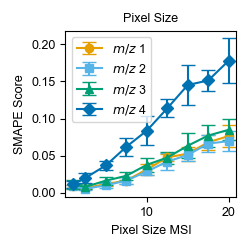

In [21]:
colors = ['#E69F00', '#56B4E9', '#009E73', '#0072B2']
markers = ['o', 's', '^', 'D']
labels = ['$\mathit{m/z}$ 1', '$\mathit{m/z}$ 2', '$\mathit{m/z}$ 3', '$\mathit{m/z}$ 4']
plt.figure(figsize=(2.5,2.5))
for i, mz in enumerate(['m/z 0', 'm/z 1', 'm/z 2', 'm/z 3']):
    plt.errorbar(mean_spacing['ms_spacing'], mean_spacing[mz], yerr=std_spacing[mz], label=labels[i], color=colors[i], marker=markers[i], fmt='o-', capsize=5)
plt.xlabel('Pixel Size MSI')
plt.ylabel('SMAPE Score')
plt.title('Pixel Size')
plt.legend()
plt.tight_layout()
plt.savefig(path + "/evaluation/ms_spacing_results.png", dpi=600)
plt.show()

C:\Users\schwenzj\AppData\Local\Temp\ipykernel_27372\766395221.py:7: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


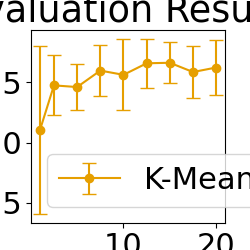

In [18]:
plt.figure(figsize=(2.5,2.5))
plt.errorbar(mean_spacing['ms_spacing'], mean_spacing['ARI'], yerr=std_spacing['ARI'], label='K-Means Clustering', color=colors[0], fmt='o-', capsize=5)
plt.xlabel('MS Spacing')
plt.ylabel('ARI')
plt.title('Evaluation Results')
plt.legend()
plt.tight_layout()
plt.savefig(path + "/evaluation/ms_spacing_ARI_results.png", dpi=600)
plt.show()